In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [26]:
A=pd.read_csv('digitsnpixels csv')

In [27]:
A.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [28]:
print('Dataset Shape :: ',A.shape)

Dataset Shape ::  (42000, 785)


In [5]:
display(df.iloc[:5,:12])

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10
0,1,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0


In [29]:
print("First five columns:")
print(df.columns[:5])

print("\nFirst 10 original labels:")
print(df["label"].head(10).tolist())

First five columns:
Index(['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3'], dtype='object')

First 10 original labels:
[1, 0, 1, 4, 0, 0, 7, 3, 5, 3]


In [30]:
if "label" not in A.columns:
    raise ValueError("The dataset does not contain a column named 'label'.")

print("Missing values:", A.isnull().sum().sum())
print("Available labels:", sorted(A["label"].unique()))
print("First 10 labels:", A["label"].head(10).tolist())

Missing values: 0
Available labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
First 10 labels: [1, 0, 1, 4, 0, 0, 7, 3, 5, 3]


In [31]:
# y contains correct digit labels
y = A["label"].to_numpy(dtype="int64")

# X contains only pixel columns
X = A.drop(columns=["label"]).to_numpy(dtype="float32")

print("X before reshaping:", X.shape)
print("y shape:", y.shape)
print("Pixel range before normalization:", X.min(), "to", X.max())

# Normalize pixel values from 0–255 to 0–1
X = X / 255.0

# Convert every row into a 28×28 grayscale image
X = X.reshape(-1, 28, 28, 1)

print("X after reshaping:", X.shape)
print("Pixel range after normalization:", X.min(), "to", X.max())

X before reshaping: (42000, 784)
y shape: (42000,)
Pixel range before normalization: 0.0 to 255.0
X after reshaping: (42000, 28, 28, 1)
Pixel range after normalization: 0.0 to 1.0


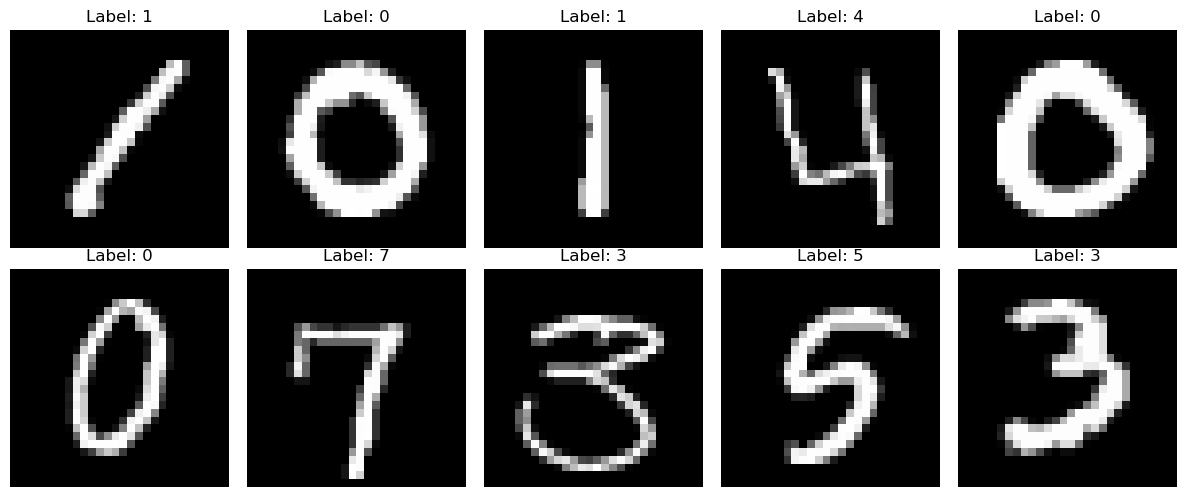

In [32]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[i].squeeze(), cmap="gray")
    plt.title(f"Label: {y[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [33]:
# 80% training and 20% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Divide temporary data into 10% validation and 10% testing
X_validation, X_test, y_validation, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_validation.shape, y_validation.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (33600, 28, 28, 1) (33600,)
Validation: (4200, 28, 28, 1) (4200,)
Testing: (4200, 28, 28, 1) (4200,)


In [34]:
# Remove any old TensorFlow model
tf.keras.backend.clear_session()

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    tf.keras.layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.30),

    tf.keras.layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [35]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_validation, y_validation),
    epochs=15,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
525/525 ━━━━━━━━━━━━━━━━━━━━ 17s 28ms/step - accuracy: 0.9236 - loss: 0.2485 - val_accuracy: 0.9767 - val_loss: 0.0752
Epoch 2/15
525/525 ━━━━━━━━━━━━━━━━━━━━ 15s 29ms/step - accuracy: 0.9762 - loss: 0.0777 - val_accuracy: 0.9860 - val_loss: 0.0479
Epoch 3/15
525/525 ━━━━━━━━━━━━━━━━━━━━ 14s 28ms/step - accuracy: 0.9834 - loss: 0.0543 - val_accuracy: 0.9850 - val_loss: 0.0533
Epoch 4/15
525/525 ━━━━━━━━━━━━━━━━━━━━ 16s 29ms/step - accuracy: 0.9870 - loss: 0.0414 - val_accuracy: 0.9869 - val_loss: 0.0459
Epoch 5/15
525/525 ━━━━━━━━━━━━━━━━━━━━ 20s 29ms/step - accuracy: 0.9892 - loss: 0.0331 - val_accuracy: 0.9895 - val_loss: 0.0431
Epoch 6/15
525/525 ━━━━━━━━━━━━━━━━━━━━ 15s 29ms/step - accuracy: 0.9905 - loss: 0.0288 - val_accuracy: 0.9879 - val_loss: 0.0424
Epoch 7/15
525/525 ━━━━━━━━━━━━━━━━━━━━ 20s 28ms/step - accuracy: 0.9925 - loss: 0.0230 - val_accuracy: 0.9898 - val_loss: 0.0437
Epoch 8/15
525/525 ━━━━━━━━━━━━━━━━━━━━ 15s 29ms/step - accuracy: 0.9935 - loss: 0.0189 - 

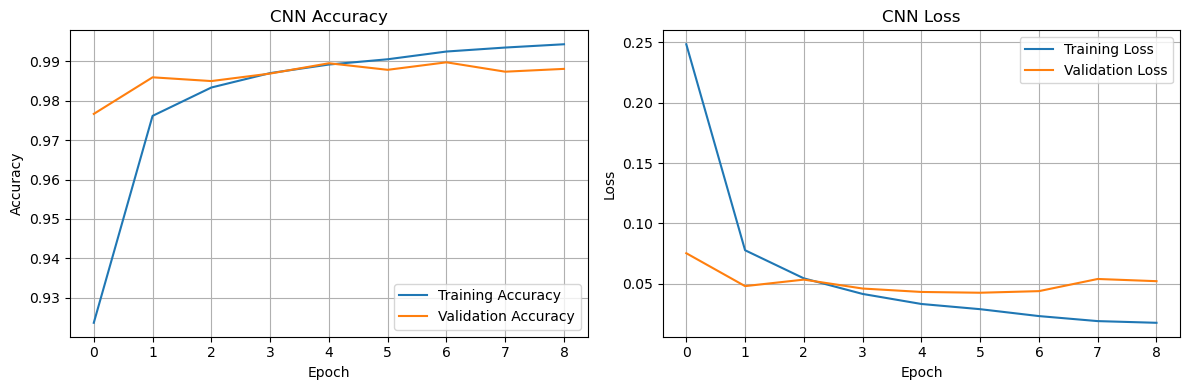

In [36]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [37]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

Test loss: 0.0406
Test accuracy: 98.60%


In [38]:
prediction_probabilities = model.predict(
    X_test,
    verbose=0
)

y_predicted = np.argmax(
    prediction_probabilities,
    axis=1
)

print("Actual labels:   ", y_test[:10])
print("Predicted labels:", y_predicted[:10])

Actual labels:    [9 1 5 3 6 0 7 5 7 1]
Predicted labels: [9 1 5 3 6 0 7 5 7 1]


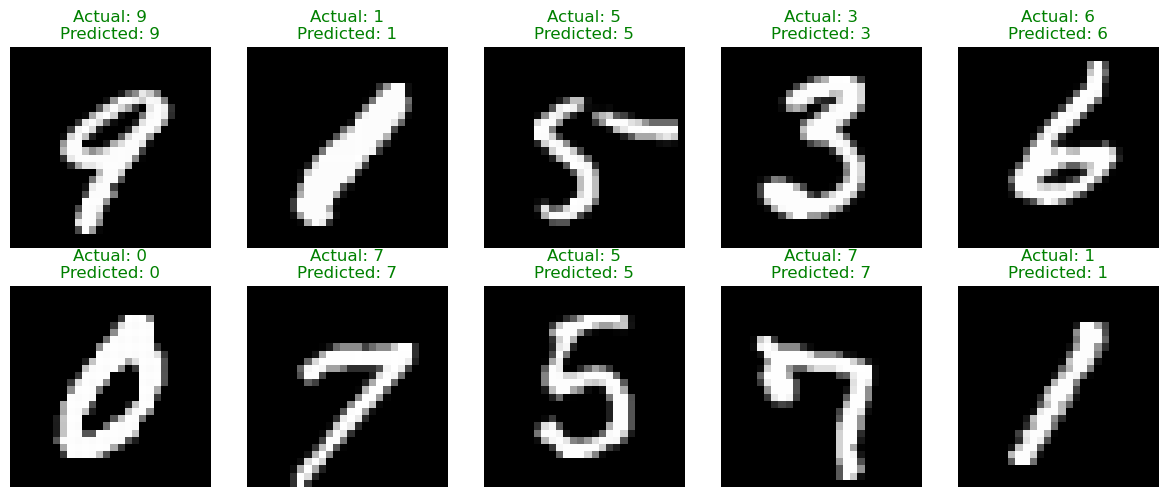

In [39]:
plt.figure(figsize=(12, 5))

for i in range(10):
    predicted_label = y_predicted[i]
    actual_label = y_test[i]

    title_color = "green" if predicted_label == actual_label else "red"

    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].squeeze(), cmap="gray")
    plt.title(
        f"Actual: {actual_label}\nPredicted: {predicted_label}",
        color=title_color
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [41]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

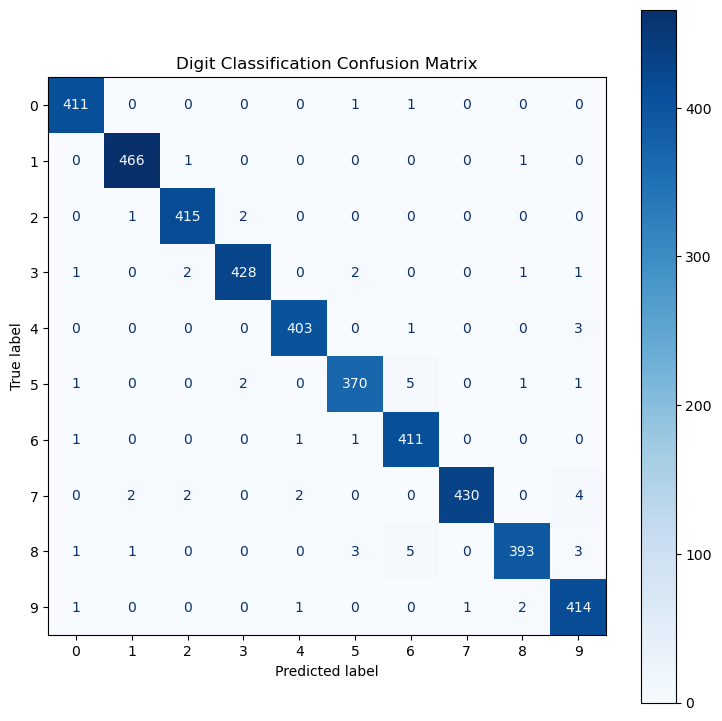

In [43]:
matrix = confusion_matrix(y_test, y_predicted)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=range(10)
)

fig, ax = plt.subplots(figsize=(9, 9))

display_matrix.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("Digit Classification Confusion Matrix")
plt.show()

In [44]:
print(
    classification_report(
        y_test,
        y_predicted,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.9880    0.9952    0.9916       413
           1     0.9915    0.9957    0.9936       468
           2     0.9881    0.9928    0.9905       418
           3     0.9907    0.9839    0.9873       435
           4     0.9902    0.9902    0.9902       407
           5     0.9814    0.9737    0.9775       380
           6     0.9716    0.9928    0.9821       414
           7     0.9977    0.9773    0.9874       440
           8     0.9874    0.9680    0.9776       406
           9     0.9718    0.9881    0.9799       419

    accuracy                         0.9860      4200
   macro avg     0.9858    0.9858    0.9858      4200
weighted avg     0.9860    0.9860    0.9859      4200



In [45]:
model.save("digits_cnn_model.keras")

print("Model saved successfully.")

Model saved successfully.
